# HW 01: Text Classification, Dependency Trees, and Word Senses

### This homework has three tasks:
1) Customer-support message triage with a PyTorch MLP (Banking77) — **7 pts**
2) Validating dependency trees — **5 pts**
3) Word Sense Disambiguation with the original Lesk algorithm (WordNet + SemCor) — **8 pts**

**BONUS:** Solve any task with an LLM — **2 pts**

#### Total: 20 points (+2 bonus)

**Rules**
- Complete only the regions between `## YOUR_CODE_STARTS_HERE` and `## YOUR_CODE_ENDS_HERE`. Do not change the provided code, function signatures, seeds, or hyperparameters.
- The code follows PS 01 and PS 02 (e.g., `build_vocab`, `SimpleMLP`, the training step, `re.findall`, `wn.synsets`), so you can look up similar code there.
- All tasks are deterministic: if you follow the instructions, your printed output matches the `TESTS & EXPECTED OUTPUT` cell after each task (It's normal if there are minor differences in the decimal points since floating point calculations can differ based on the hardware).
- **Hardcoding answers to match the expected output (e.g., returning fixed values or special-casing inputs) gives 0 points for the whole task.**

## Pre-requisite code

The code in this section will be used in the tasks. **Do not change these lines.**

The Task 1 cell needs internet access: it downloads the Banking77 dataset from GitHub.

In [1]:
# Colab setup: NumPy, pandas, PyTorch, and NLTK are pre-installed in Google Colab.
# This cell downloads the NLTK resources used in Tasks 1-3 (about 15 MB).
import sys

import nltk


def nltk_resource_available(lookup_paths: tuple[str, ...]) -> bool:
    """Return True when any accepted path for an NLTK resource exists."""
    for lookup_path in lookup_paths:
        try:
            nltk.data.find(lookup_path)
            return True
        except LookupError:
            pass
    return False


required_nltk_resources = {
    "wordnet": ("corpora/wordnet", "corpora/wordnet.zip"),
    "semcor": ("corpora/semcor", "corpora/semcor.zip"),
    "dependency_treebank": ("corpora/dependency_treebank", "corpora/dependency_treebank.zip"),
    "stopwords": ("corpora/stopwords", "corpora/stopwords.zip"),
}

for resource, lookup_paths in required_nltk_resources.items():
    if not nltk_resource_available(lookup_paths):
        print(f"Downloading NLTK resource: {resource}")
        if not nltk.download(resource, quiet=True):
            raise RuntimeError(f"Could not download NLTK resource: {resource}")

print(f"Python: {sys.version.split()[0]}")
print("NLTK resources are ready")

Python: 3.13.16
NLTK resources are ready


In [2]:
# Shared imports and seeds.
import math
import random
import re
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from nltk.corpus import dependency_treebank, semcor, stopwords
from nltk.corpus import wordnet as wn
from nltk.corpus.reader.wordnet import Lemma
from nltk.stem import WordNetLemmatizer
from nltk.tree import Tree
from torch.utils.data import DataLoader, TensorDataset

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Shared helpers are ready")

Shared helpers are ready


### Task 1: data and helpers

The next cell prepares everything Task 1 needs:
- downloads **Banking77** from GitHub and keeps 18 intents: 9 urgent (label `1`) and 9 routine (label `0`); the official training file is split 85/15 into `train_df` and `dev_df` with a fixed seed, and the official test file becomes `test_df`;
- defines `STOP_WORDS`: NLTK's English stopword list **without the negations** (`no`, `nor`, `not`, and every word ending in `n't`), because negations matter in complaints such as *I didn't make this payment*;
- defines `build_vocab(...)`, which works like `build_vocab` in PS 01: tokens seen at least `min_count` times get IDs in the order of their first occurrence;
- prints the split sizes, the number of stopwords, and a few example messages.

In [3]:
# Task 1 data: Banking77, real customer-support messages sent to an online bank
# (Casanueva et al., 2020, CC BY 4.0). We keep 18 of its 77 intents and group them into
# urgent incidents (label 1) and routine requests (label 0).
BANKING77_URL = (
    "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/"
    "master/banking_data/{split}.csv"
)
URGENT_INTENTS = [
    "lost_or_stolen_card", "compromised_card", "card_swallowed",
    "card_payment_not_recognised", "cash_withdrawal_not_recognised",
    "direct_debit_payment_not_recognised", "transaction_charged_twice",
    "pin_blocked", "lost_or_stolen_phone",
]
ROUTINE_INTENTS = [
    "card_delivery_estimate", "exchange_rate", "supported_cards_and_currencies",
    "country_support", "age_limit", "top_up_limits",
    "change_pin", "card_payment_fee_charged", "getting_spare_card",
]

# NLTK's English stopword list without the negations: "no", "nor", "not", and every contraction ending in
# "n't" carry meaning in complaints such as "I didn't make this payment".
NLTK_STOP_WORDS = set(stopwords.words("english"))
NEGATIONS = {"no", "nor", "not"} | {word for word in NLTK_STOP_WORDS if word.endswith("n't")}
STOP_WORDS = NLTK_STOP_WORDS - NEGATIONS


def load_banking77_triage() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Download Banking77, keep the triage intents, and split it into train/dev/test (as in PS 01)."""
    frames = {}
    for split in ("train", "test"):
        frame = pd.read_csv(BANKING77_URL.format(split=split))
        frame = frame[frame["category"].isin(URGENT_INTENTS + ROUTINE_INTENTS)]
        frame = frame.assign(label=frame["category"].isin(URGENT_INTENTS).astype(int))
        frames[split] = frame.reset_index(drop=True)
    # Shuffle 0, 1, ..., n-1 once; the seed makes this shuffle repeatable.
    indices = np.random.default_rng(RANDOM_SEED).permutation(len(frames["train"]))
    dev_end = int(0.15 * len(indices))
    dev = frames["train"].iloc[indices[:dev_end]].reset_index(drop=True)
    train = frames["train"].iloc[indices[dev_end:]].reset_index(drop=True)
    return train, dev, frames["test"]


def build_vocab(tokenized_texts: list[list[str]], min_count: int = 2) -> dict[str, int]:
    """Map every token seen at least min_count times to an ID, in order of first occurrence (as in PS 01)."""
    counts = Counter(token for tokens in tokenized_texts for token in tokens)
    vocab = {}
    for tokens in tokenized_texts:
        for token in tokens:
            if counts[token] >= min_count and token not in vocab:
                vocab[token] = len(vocab)  # use the current size as the next ID
    return vocab


train_df, dev_df, test_df = load_banking77_triage()
print(f"Task 1: {len(train_df)} train, {len(dev_df)} dev, and {len(test_df)} test messages")
print(f"STOP_WORDS: {len(STOP_WORDS)} words (NLTK's {len(NLTK_STOP_WORDS)} English stopwords without {len(NEGATIONS)} negations)")
for label, name in [(1, "urgent"), (0, "routine")]:
    print(f"Examples of {name} messages:")
    for _, row in train_df[train_df["label"] == label].head(2).iterrows():
        print(f"  [{row['category']}] {row['text']}")

Task 1: 1936 train, 341 dev, and 720 test messages
STOP_WORDS: 177 words (NLTK's 198 English stopwords without 21 negations)
Examples of urgent messages:
  [direct_debit_payment_not_recognised] Purchases I did not make are appearing in my bank statement?
  [cash_withdrawal_not_recognised] I see an unauthorized withdraw.
Examples of routine messages:
  [card_payment_fee_charged] I have been charged a fee, I didn't know about this fee before! When do you charge extra for card payments?
  [getting_spare_card] Can I have a duplicate second card?


### Task 2: data and helpers

The next cell prepares everything Task 2 needs:
- `make_tree(...)`: a tree is a dictionary with `"tokens"` (`tokens[0]` is `ROOT`) and `"arcs"`, a list of `(head, dependent, relation)` triples;
- `EXAMPLE_TREES`: both readings of *I saw the man with the telescope.* (PS 02), the non-projective cat sentence, and three corrupted trees;
- `print_tree(...)`: the PS 02 parse table (token, relation, head, children);
- `reachable_from(arcs, start)`: all nodes reached from `start` by following arcs down to the children; your functions use it;
- `TREEBANK_TREES`: 3,914 gold trees from NLTK's sample of the Penn Treebank (Wall Street Journal), converted to the same format;
- prints one example tree as a table and as a list of arcs.

In [4]:
# Task 2 data. A tree lists its tokens, with the artificial ROOT at index 0, and its arcs
# (head, dependent, relation). An arc i -> j points from the head i to its dependent j.
def make_tree(words: list[str], arcs: list[tuple[int, int, str]]) -> dict:
    """Bundle the words (ROOT is added at index 0) and the arcs of one tree."""
    return {"tokens": ["ROOT"] + words, "arcs": arcs}


# The attachment-ambiguous sentence of PS 02: did I use the telescope (instrument reading),
# or did the man have it (modifier reading)? Only the head of "with" differs.
TELESCOPE_WORDS = ["I", "saw", "the", "man", "with", "the", "telescope", "."]
INSTRUMENT_ARCS = [(0, 2, "root"), (2, 1, "nsubj"), (4, 3, "det"), (2, 4, "dobj"), (2, 5, "prep"),
                   (7, 6, "det"), (5, 7, "pobj"), (2, 8, "punct")]
MODIFIER_ARCS = [arc for arc in INSTRUMENT_ARCS if arc[:2] != (2, 5)] + [(4, 5, "prep")]
# A well-formed but non-projective tree: the relative clause "which was black" belongs to "cat",
# but "yesterday" (a child of "saw") stands between "cat" and "black".
CAT_WORDS = "I saw a cat yesterday which was black".split()
CAT_ARCS = [(0, 2, "root"), (2, 1, "nsubj"), (4, 3, "det"), (2, 4, "obj"), (2, 5, "obl"),
            (8, 6, "nsubj"), (8, 7, "cop"), (4, 8, "acl:relcl")]

EXAMPLE_TREES = {
    "instrument reading": make_tree(TELESCOPE_WORDS, INSTRUMENT_ARCS),
    "modifier reading": make_tree(TELESCOPE_WORDS, MODIFIER_ARCS),
    "cat sentence (non-projective)": make_tree(CAT_WORDS, CAT_ARCS),
    "corrupted: extra arc saw -> with": make_tree(TELESCOPE_WORDS, MODIFIER_ARCS + [(2, 5, "prep")]),
    "corrupted: with <-> telescope": make_tree(
        TELESCOPE_WORDS, [arc for arc in INSTRUMENT_ARCS if arc[:2] != (2, 5)] + [(7, 5, "prep")]),
    "corrupted: no ROOT arc": make_tree(TELESCOPE_WORDS, INSTRUMENT_ARCS[1:]),
}


def print_tree(tree: dict) -> None:
    """Print one row per word with its relation, head, and children, like the PS 02 parse table."""
    tokens, arcs = tree["tokens"], tree["arcs"]
    print(f"{'Token':<14} {'Relation':<10} {'Head':<14} Children")
    print("-" * 56)
    for index in range(1, len(tokens)):
        heads = [(head, relation) for head, dependent, relation in arcs if dependent == index]
        head_text = ", ".join(f"{head}:{tokens[head]}" for head, _ in heads) or "-"
        relation = ", ".join(relation for _, relation in heads) or "-"
        children = ", ".join(f"{dependent}:{tokens[dependent]}" for head, dependent, _ in arcs if head == index) or "-"
        print(f"{f'{index}:{tokens[index]}':<14} {relation:<10} {head_text:<14} {children}")


def reachable_from(arcs: list[tuple[int, int, str]], start: int) -> set[int]:
    """Return every node reached from start by following one or more arcs down to the children (as in PS 02).

    start itself is in the result only if it lies on a cycle; the set of reached nodes stops the search on cycles.
    """
    children = {}
    for head, dependent, _ in arcs:
        children.setdefault(head, []).append(dependent)
    reached, stack = set(), [start]
    while stack:
        node = stack.pop()
        for child in children.get(node, []):
            if child not in reached:
                reached.add(child)
                stack.append(child)
    return reached


def load_treebank_trees() -> list[dict]:
    """Convert NLTK's dependency treebank sample (WSJ part of the Penn Treebank) into our format."""
    trees = []
    for graph in dependency_treebank.parsed_sents():
        num_words = len(graph.nodes) - 1
        words = [graph.nodes[index]["word"] for index in range(1, num_words + 1)]
        arcs = [(graph.nodes[index]["head"], index, graph.nodes[index]["rel"] or "dep")
                for index in range(1, num_words + 1)]
        trees.append(make_tree(words, arcs))
    return trees


TREEBANK_TREES = load_treebank_trees()
print(f"Task 2: {len(EXAMPLE_TREES)} example trees and {len(TREEBANK_TREES)} treebank trees\n")
print("The instrument reading of 'I saw the man with the telescope.' (index:token):")
print_tree(EXAMPLE_TREES["instrument reading"])
print("\nThe arcs of the same tree, as (head, dependent, relation):")
print(EXAMPLE_TREES["instrument reading"]["arcs"])

Task 2: 6 example trees and 3914 treebank trees

The instrument reading of 'I saw the man with the telescope.' (index:token):
Token          Relation   Head           Children
--------------------------------------------------------
1:I            nsubj      2:saw          -
2:saw          root       0:ROOT         1:I, 4:man, 5:with, 8:.
3:the          det        4:man          -
4:man          dobj       2:saw          3:the
5:with         prep       2:saw          7:telescope
6:the          det        7:telescope    -
7:telescope    pobj       5:with         6:the
8:.            punct      2:saw          -

The arcs of the same tree, as (head, dependent, relation):
[(0, 2, 'root'), (2, 1, 'nsubj'), (4, 3, 'det'), (2, 4, 'dobj'), (2, 5, 'prep'), (7, 6, 'det'), (5, 7, 'pobj'), (2, 8, 'punct')]


### Task 3: data and helpers

The next cell prepares everything Task 3 needs:
- `WSD_STOP_WORDS`: NLTK's English stopword list;
- `lemmatize(...)` and `content_tokens(...)`: lowercase alphabetic tokens without stopwords and one-letter tokens, turned into noun lemmas with `WordNetLemmatizer` (as in PS 02);
- `all_sense_definitions(word)`: the definitions of all WordNet senses of a word;
- `WSD_EXAMPLES`: occurrences of ambiguous nouns from the first 40 SemCor files, each with its gold WordNet sense;
- `random_baseline_accuracy(...)`: the expected accuracy of choosing a sense at random;
- prints the first example, its content tokens, and the WordNet senses of its target.

In [5]:
# Task 3 data: WordNet 3.0 senses, and SemCor, a part of the Brown corpus whose content words were
# annotated by hand with WordNet senses (Miller et al., 1993). We use the first 40 SemCor files.
WSD_STOP_WORDS = set(stopwords.words("english"))  # NLTK's English stopword list


lemmatizer = WordNetLemmatizer()  # as in PS 02; lemmatize() uses the noun POS by default


def lemmatize(token: str) -> str:
    """Return the noun lemma of a lowercase token, e.g. 'boats' -> 'boat'."""
    return lemmatizer.lemmatize(token)


def content_tokens(text: str) -> list[str]:
    """Lowercase, keep alphabetic tokens, drop stopwords and one-letter tokens, then lemmatize."""
    tokens = re.findall(r"[a-z]+", text.lower())
    return [lemmatize(token) for token in tokens if token not in WSD_STOP_WORDS and len(token) > 1]


def all_sense_definitions(word: str) -> tuple[str, ...]:
    """Return the definitions of every WordNet sense of a word, for all parts of speech."""
    return tuple(synset.definition() for synset in wn.synsets(word))


def load_semcor_wsd_examples(num_files: int = 40, min_examples: int = 20, min_observed_senses: int = 3,
                             max_senses: int = 12) -> list[dict[str, str]]:
    """Collect sense-annotated occurrences of ambiguous nouns from the first SemCor files."""
    occurrences = {}
    for sentence in semcor.tagged_sents(semcor.fileids()[:num_files], tag="sem"):
        words, senses = [], []
        for chunk in sentence:
            if isinstance(chunk, Tree):
                words.append(" ".join(chunk.leaves()))
                senses.append(chunk.label() if isinstance(chunk.label(), Lemma) else None)
            else:
                words.append(" ".join(chunk))
                senses.append(None)
        text = " ".join(words)
        for word, sense in zip(words, senses):
            if sense is None or sense.synset().pos() != "n" or " " in word:
                continue
            target = sense.name().lower()
            if lemmatize(word.lower()) != target:  # skips named-entity labels such as "person"
                continue
            occurrences.setdefault(target, []).append(
                {"target": target, "sentence": text, "gold": sense.synset().name()})
    examples = []
    for target in sorted(occurrences):
        items = occurrences[target]
        if (len(items) >= min_examples and len({item["gold"] for item in items}) >= min_observed_senses
                and len(wn.synsets(target, pos=wn.NOUN)) <= max_senses):
            examples.extend(items)
    return examples


def random_baseline_accuracy(examples: list[dict[str, str]]) -> float:
    """Baseline: expected accuracy of choosing one of the target's noun senses uniformly at random."""
    return float(np.mean([1 / len(wn.synsets(item["target"], pos=wn.NOUN)) for item in examples]))


WSD_EXAMPLES = load_semcor_wsd_examples()
print(f"Task 3: {len(WSD_EXAMPLES)} SemCor examples of {len({item['target'] for item in WSD_EXAMPLES})} "
      f"ambiguous nouns")
print("First example:", WSD_EXAMPLES[0])
print("Its content tokens:", content_tokens(WSD_EXAMPLES[0]["sentence"]))
print(f"\nNoun senses of {WSD_EXAMPLES[0]['target']!r} in WordNet order (as in PS 02):")
for synset in wn.synsets(WSD_EXAMPLES[0]["target"], pos=wn.NOUN):
    print(f"  {synset.name():<16} {synset.definition()}")

Task 3: 2355 SemCor examples of 68 ambiguous nouns
First example: {'target': 'action', 'sentence': "`` These actions should serve to protect in fact and in effect the court 's wards from undue costs and its appointed and elected servants from unmeritorious criticisms '' , the jury said .", 'gold': 'action.n.01'}
Its content tokens: ['action', 'serve', 'protect', 'fact', 'effect', 'court', 'ward', 'undue', 'cost', 'appointed', 'elected', 'servant', 'unmeritorious', 'criticism', 'jury', 'said']

Noun senses of 'action' in WordNet order (as in PS 02):
  action.n.01      something done (usually as opposed to something said)
  action.n.02      the state of being active
  military_action.n.01 a military engagement
  natural_process.n.01 a process existing in or produced by nature (rather than by the intent of human beings)
  action.n.05      the series of events that form a plot
  action.n.06      the trait of being active and energetic and forceful
  action.n.07      the operating part that

# TASK 1 (7 pts): Customer-support message triage with a PyTorch MLP

**High-level overview.**
Build a **binary classifier** that sends real customer-support messages of an online bank to an **urgent** queue (`1`: lost card, unrecognised payment, blocked PIN, ...) or a **routine** queue (`0`: delivery time, exchange rate, fees, ...). The messages come from the public **Banking77** dataset. The pipeline is the one of the PS 01 MLP demo, applied to text: (1) tokenize the messages, (2) turn them into **count vectors**, and (3) train an **MLP in PyTorch** with mini-batches and a dev split.

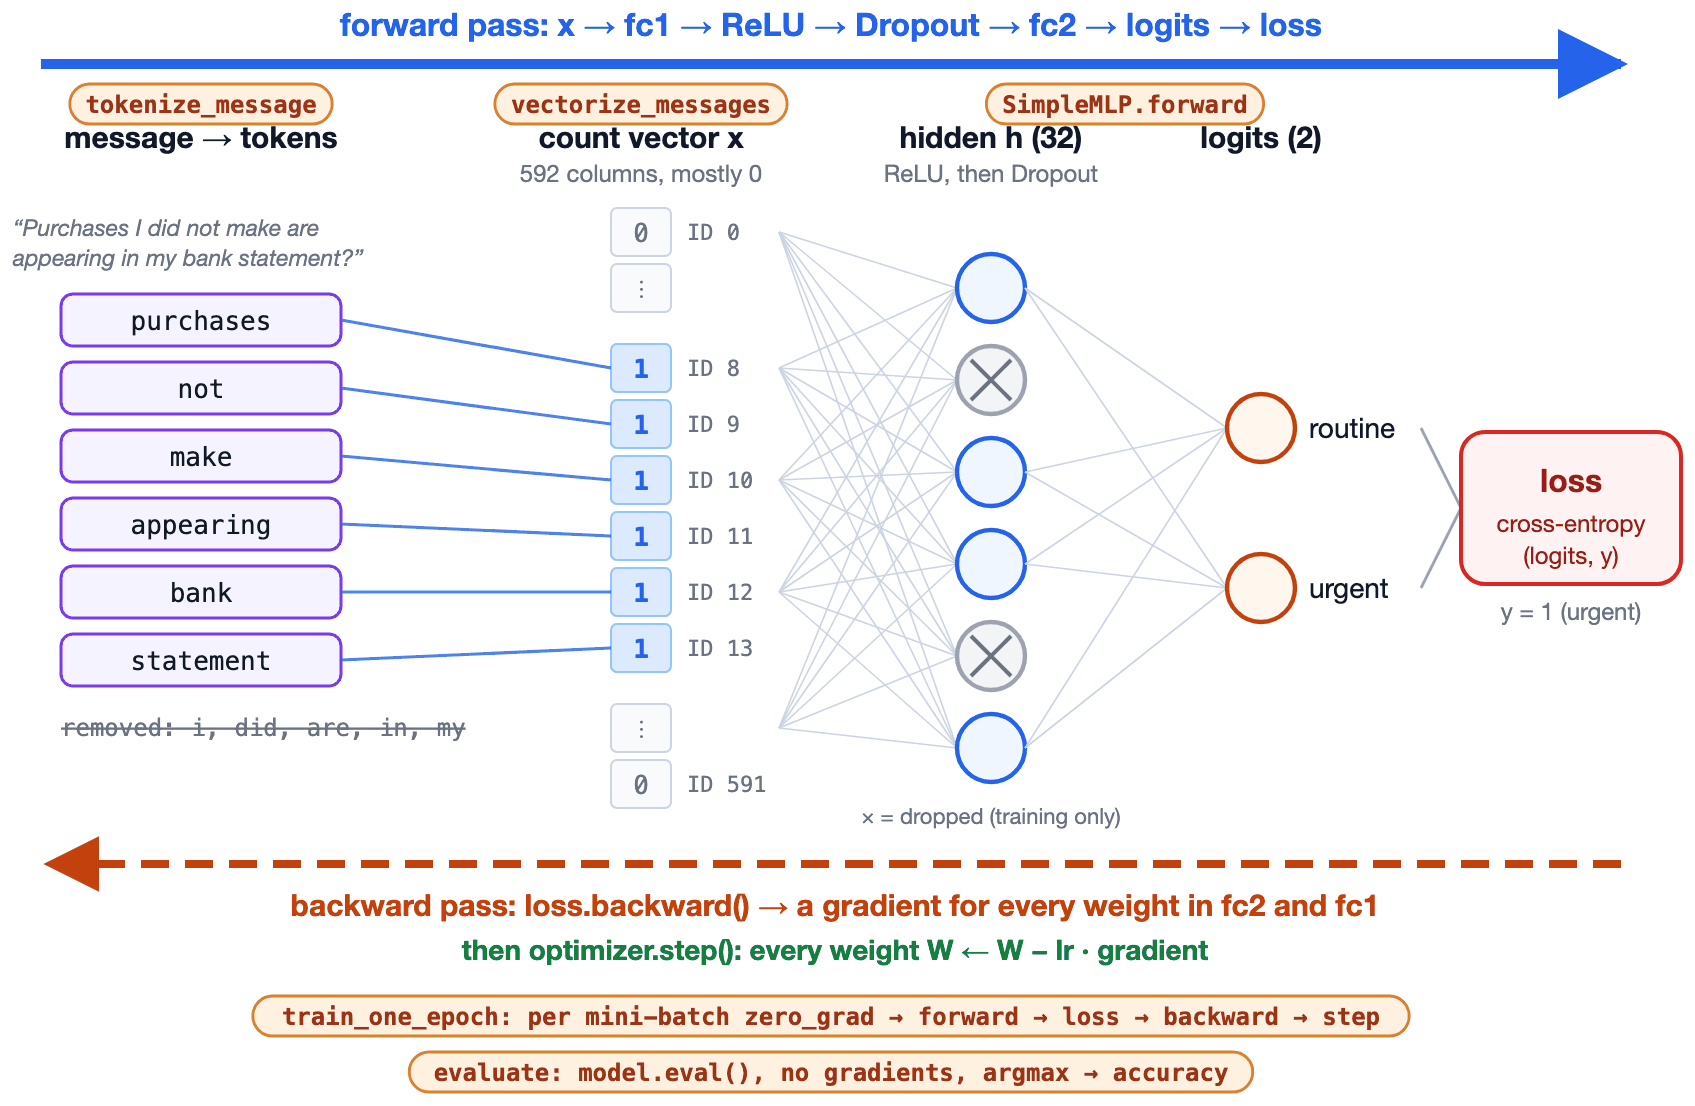

The orange labels name the five functions you write; everything else is provided.

---

### What is provided
- `train_df`, `dev_df`, `test_df` with the columns `text`, `category` (intent), and `label`.
- `STOP_WORDS` (it keeps the negations `no`, `not`, `nor`) and `build_vocab(...)`, which works like `build_vocab` in PS 01 and is fitted on the training split.
- The `SimpleMLP` layers (as in PS 01, plus one `Dropout` layer), the DataLoaders, the optimizer, the epoch loop, and the test evaluation.

---

### What you should implement
1) `tokenize_message` — lowercase the text, extract tokens with `re.findall(r"[a-z]+(?:'[a-z]+)?", ...)` (as in PS 02), and remove `STOP_WORDS`; return the tokens as a list, in their original order.
2) `vectorize_messages` — return the **count matrix** as a NumPy array (`np.ndarray`) with `dtype=np.float32` and shape `(len(texts), len(vocab))`: entry `[i, vocab[token]]` counts how often `token` occurs in message `i`. Ignore tokens that are not in `vocab`.
3) `SimpleMLP.forward` — apply `fc1 → ReLU → Dropout → fc2` (as in PS 01, plus dropout) and return the logits, a tensor of shape `(batch_size, 2)` (no softmax).
4) `train_one_epoch` — the PS 01 training step for **every mini-batch**, in this order: `zero_grad`, forward, loss, `backward`, `step`. Return the **mean training loss per message** as a `float`: $\frac{1}{N}\sum_{\text{batches}} \text{loss} \cdot \text{batch size}$.
5) `evaluate` — use `model.eval()`, no gradients (`torch.no_grad()`), `argmax` of the logits; return the accuracy as a `float` between 0 and 1.

---

### Grading (7 pts)
One sub-task per function above:
- **1.1** `tokenize_message`: regex, stopwords, negations — **1.5 pts**
- **1.2** `vectorize_messages`: `float32` count matrix of the right shape, unknown tokens ignored — **1.5 pts**
- **1.3** `SimpleMLP.forward`: `fc1 → ReLU → Dropout → fc2`, returns logits — **1.0 pt**
- **1.4** `train_one_epoch`: step order and mean loss per message; the epoch lines match the expected output — **2.0 pts**
- **1.5** `evaluate`: evaluation mode, no gradients, accuracy; the test accuracy matches the expected output — **1.0 pt**

> **Tips**
> • The seeds are fixed, so your epoch lines should match the expected output. If they do not, check the order of the training step and the mean-loss formula, and call the model once per mini-batch.
> • Training runs on the CPU in a few seconds.

In [7]:
def tokenize_message(text: str) -> list[str]:
    """Return the lowercase content tokens of one message in their original order."""
    return content_tokens(text)
    pass
    return content_tokens(text)


def vectorize_messages(texts: list[str], vocab: dict[str, int]) -> np.ndarray:
    """Return a float32 count matrix with one row per message and one column per vocabulary ID."""
    return np.array([[text.lower().split().count(token) for token in vocab] for text in texts], dtype=np.float32)
    pass
    return np.array([[text.lower().split().count(token) for token in vocab] for text in texts], dtype=np.float32)


class SimpleMLP(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_classes: int, dropout: float) -> None:
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return raw class scores (logits) of shape (batch_size, num_classes)."""
        return self.fc2(self.dropout(self.relu(self.fc1(x))))
        pass
        return self.fc2(self.dropout(self.relu(self.fc1(x))))


# Features: the vocabulary is built from the training split only.
train_tokens = [tokenize_message(text) for text in train_df["text"]]
vocab = build_vocab(train_tokens, min_count=2)
X_train = torch.from_numpy(vectorize_messages(train_df["text"].tolist(), vocab))
X_dev = torch.from_numpy(vectorize_messages(dev_df["text"].tolist(), vocab))
X_test = torch.from_numpy(vectorize_messages(test_df["text"].tolist(), vocab))
y_train = torch.tensor(train_df["label"].values, dtype=torch.long)
y_dev = torch.tensor(dev_df["label"].values, dtype=torch.long)
y_test = torch.tensor(test_df["label"].values, dtype=torch.long)
print(f"[TASK1] Vocabulary size: {len(vocab)}")
print(f"[TASK1] Feature shapes: train={tuple(X_train.shape)}, dev={tuple(X_dev.shape)}, test={tuple(X_test.shape)}")

BATCH_SIZE = 32
EPOCHS = 10
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(RANDOM_SEED))

torch.manual_seed(RANDOM_SEED)
model = SimpleMLP(input_size=X_train.shape[1], hidden_size=32, num_classes=2, dropout=0.3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch(loader: DataLoader) -> float:
    """Run one optimization step per mini-batch and return the mean training loss per message."""
    return float(np.mean([train_one_batch(X, y) for X, y in loader]))
    pass
    return float(np.mean([train_one_batch(X, y) for X, y in loader]))


def evaluate(X: torch.Tensor, y: torch.Tensor) -> float:
    """Return the accuracy of model on (X, y), without dropout and without gradients."""
    return float((model(X).argmax(dim=1) == y).sum().item() / y.size(0))
    pass 
    return float((model(X).argmax(dim=1) == y).sum().item() / y.size(0))

history = {"train_loss": [], "dev_accuracy": []}
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(train_loader)
    dev_accuracy = evaluate(X_dev, y_dev)
    history["train_loss"].append(train_loss)
    history["dev_accuracy"].append(dev_accuracy)
    print(f"[TASK1] Epoch {epoch:02d} | train loss {train_loss:.4f} | dev accuracy {dev_accuracy:.4f}")

# Test evaluation (provided)
test_accuracy = evaluate(X_test, y_test)
model.eval()
with torch.no_grad():
    test_predictions = model(X_test).argmax(dim=1)
confusion = np.zeros((2, 2), dtype=int)
for gold, predicted in zip(y_test.tolist(), test_predictions.tolist()):
    confusion[gold, predicted] += 1
print("[TASK1] Test confusion matrix [rows=gold 0/1, cols=predicted 0/1]:")
print(confusion)
print("[TASK1] First 3 misclassified test messages:")
for index in torch.nonzero(test_predictions != y_test).flatten()[:3].tolist():
    row = test_df.iloc[index]
    print(f"  gold={row['label']} predicted={test_predictions[index].item()} [{row['category']}] {row['text']}")

# RESULT_CHECKING_POINT
print(f"[TASK1 RESULT_CHECKING_POINT] Test Accuracy: {test_accuracy:.4f}")

[TASK1] Vocabulary size: 540
[TASK1] Feature shapes: train=(1936, 540), dev=(341, 540), test=(720, 540)


NameError: name 'train_one_batch' is not defined

In [ ]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. Accuracies and the confusion
# matrix should match exactly; losses may differ in the last digit on other hardware.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK1] Vocabulary size: 592
# [TASK1] Feature shapes: train=(1936, 592), dev=(341, 592), test=(720, 592)
# [TASK1] Epoch 01 | train loss 0.6346 | dev accuracy 0.9472
# [TASK1] Epoch 02 | train loss 0.3797 | dev accuracy 0.9619
# [TASK1] Epoch 03 | train loss 0.1866 | dev accuracy 0.9619
# [TASK1] Epoch 04 | train loss 0.1165 | dev accuracy 0.9736
# [TASK1] Epoch 05 | train loss 0.0856 | dev accuracy 0.9795
# [TASK1] Epoch 06 | train loss 0.0660 | dev accuracy 0.9795
# [TASK1] Epoch 07 | train loss 0.0545 | dev accuracy 0.9795
# [TASK1] Epoch 08 | train loss 0.0500 | dev accuracy 0.9765
# [TASK1] Epoch 09 | train loss 0.0421 | dev accuracy 0.9765
# [TASK1] Epoch 10 | train loss 0.0362 | dev accuracy 0.9765
# [TASK1] Test confusion matrix [rows=gold 0/1, cols=predicted 0/1]:
# [[346  14]
#  [ 10 350]]
# [TASK1] First 3 misclassified test messages:
#   gold=0 predicted=1 [card_delivery_estimate] my card was not in the mail again can you advise?
#   gold=1 predicted=0 [lost_or_stolen_card] I'm in Spain and my stuff has been stolen. My card was with it and I need a new one shipped and the old one frozen.
#   gold=1 predicted=0 [lost_or_stolen_card] Are you able to locate my card?
# [TASK1 RESULT_CHECKING_POINT] Test Accuracy: 0.9667
#
# ---------------------------------------------------------------------------

# TASK 2 (5 pts): Validating dependency trees

**High-level overview.**
A parser or a treebank conversion produces a set of arcs. Before we use them, we check that they form a **well-formed dependency tree**. In this task you do not build trees; you **validate** them with the formal conditions on dependency graphs from **PS 02**. You check six small trees, among them both readings of the PS 02 sentence *I saw the man with the telescope.*, and **3,914 real trees** from the Wall Street Journal sample of the Penn Treebank in NLTK.

**Notation.** As in PS 02, every word has one **head** and a list of **children**. Words have the indices `1..n`; the artificial `ROOT` has index `0`. An arc `(i, j, relation)` means $i \rightarrow j$: $i$ is the head of $j$. We write $i \rightarrow^{*} k$ when $k$ can be reached from $i$ by following one or more arcs.

| Condition | Definition | What you check |
|---|---|---|
| **Single head** | If $i \rightarrow j$, then not $k \rightarrow j$ for any $k \neq i$ | no node has two heads; `ROOT` has no head |
| **Connected** | every node is linked to the graph | every word can be reached from `ROOT` |
| **Acyclic** | If $i \rightarrow j$, then not $j \rightarrow^{*} i$ | no node can be reached from itself |
| **Projective** | If $i \rightarrow j$, then $i \rightarrow^{*} k$ for every $k$ between $i$ and $j$ | no crossing arcs |

In PS 02 we listed four checks together for a parse tree to be **well-formed**, including the **projective** property. In HW 01 we separate them: **well-formed** = single-head + connected + acyclic; **projective** is checked on its own. In PS 02 we showed one example implementation (**Arc-standard**), which can build only **projective** trees. In other implementations, a tree can be well-formed and still **non-projective**. Arc-standard can only build projective trees; Another parsers, e.g., spaCy may still produce non-projective ones.

So, a tree is **well-formed** if it is single-headed, connected, and acyclic. A well-formed tree can still be **non-projective**. Example: in *I saw a cat yesterday which was black*, the relative clause *which was black* belongs to *cat*, but *yesterday* stands between them (**non-projective**).

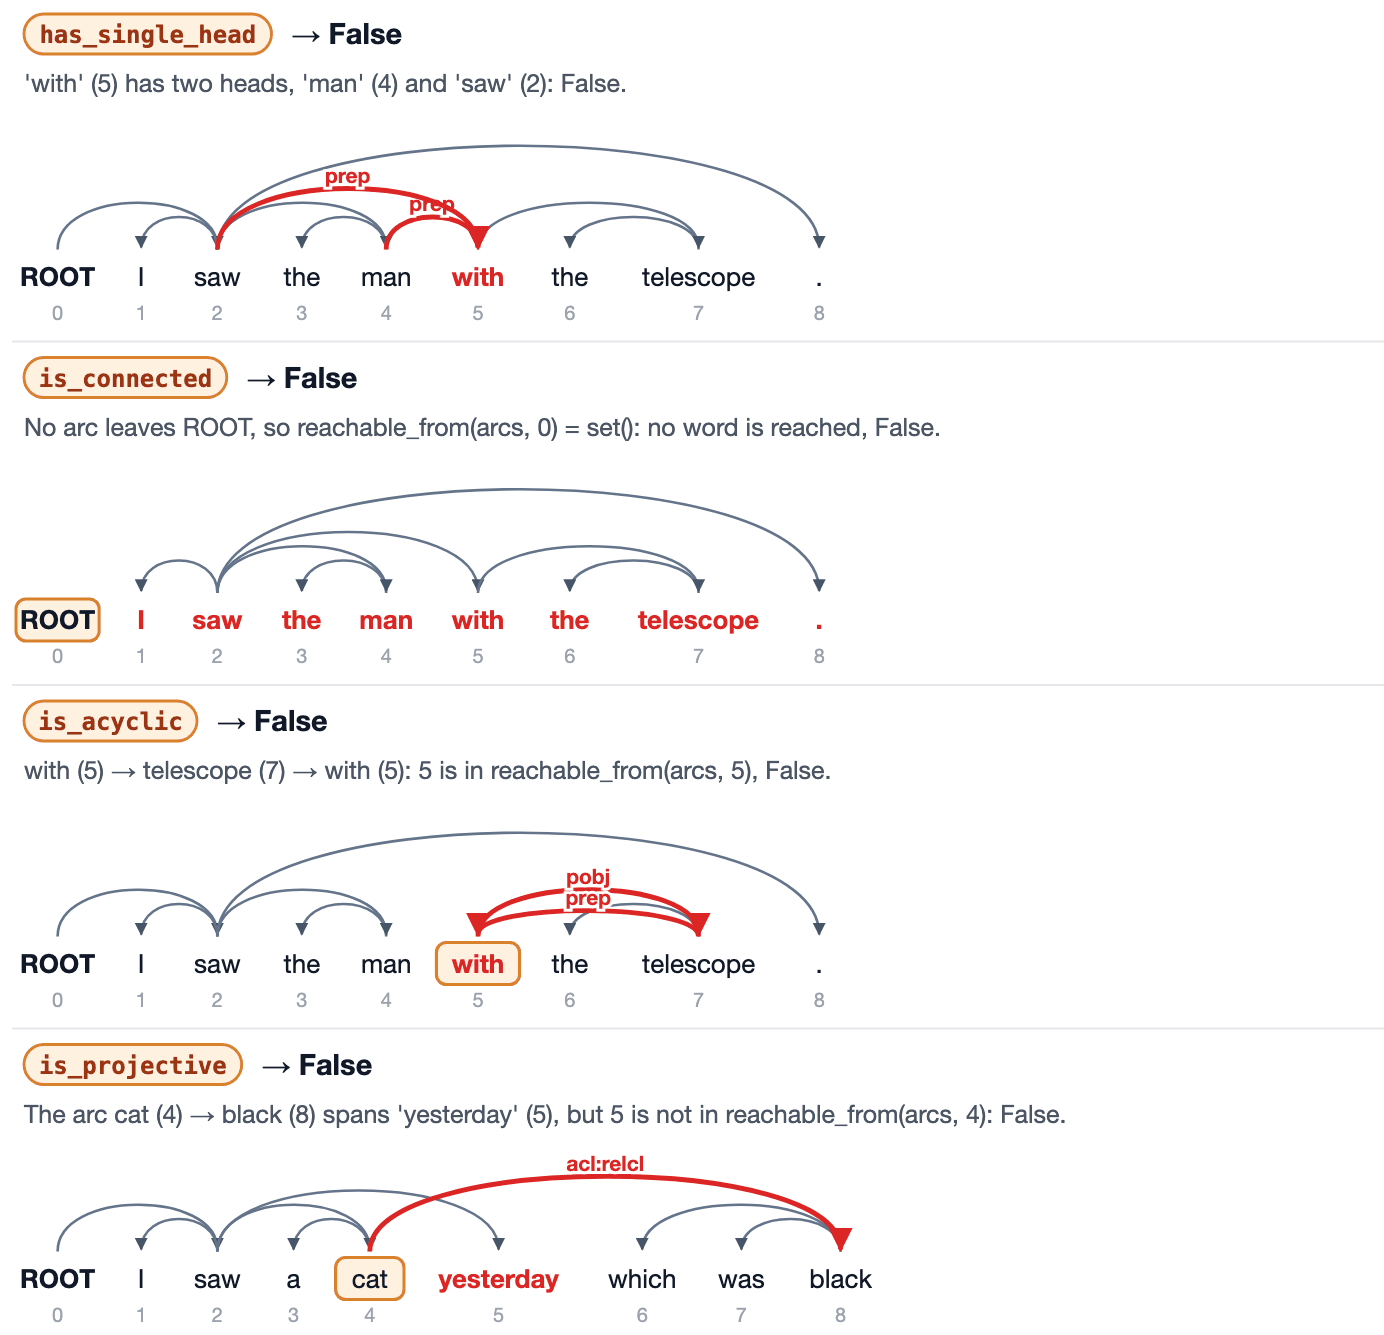

Each panel shows one of your four functions on a tree for which it must return `False`; the red arcs or words break the condition.

---

### What is provided
- `EXAMPLE_TREES` (both readings of the telescope sentence, the cat sentence, and three corrupted trees) and `TREEBANK_TREES`. Each tree is a dictionary with `"tokens"` (`tokens[0]` is `ROOT`) and `"arcs"`, a list of `(head, dependent, relation)` triples.
- `reachable_from(arcs, start)`, which returns the set of all nodes reached from `start` by following one or more arcs down to the children (`start` itself is included only if it lies on a cycle).
- `validate_dependency_tree(tree)`, which calls your four functions and adds `well_formed`; `print_tree(...)` (the PS 02 parse table); and the code that prints the results.

---

### What you should implement
Each function receives `num_words` (the number of words without `ROOT`) and `arcs`, and returns a `bool`:
1) `has_single_head` — `True` if no node has more than one head and `ROOT` (0) has no head.
2) `is_connected` — `True` if every word `1..num_words` can be reached from `ROOT` (use `reachable_from`).
3) `is_acyclic` — `True` if no node `0..num_words` can be reached from itself (use `reachable_from`).
4) `is_projective` — `True` if, for every arc `(i, j, relation)`, every word strictly between `i` and `j` can be reached from `i` (use `reachable_from`).

---

### Grading (5 pts)
One sub-task per function above; each one also checks that the table and the treebank counts match the expected output:
- **2.1** `has_single_head` — **1.0 pt**
- **2.2** `is_connected` — **1.0 pt**
- **2.3** `is_acyclic` — **1.5 pts**
- **2.4** `is_projective` — **1.5 pts**

> **Tips**
> • For `has_single_head`, count how often every node appears as a dependent (incoming arcs), e.g., with a `Counter`: each word at most once, and `ROOT` (0) never.

In [ ]:
def has_single_head(num_words: int, arcs: list[tuple[int, int, str]]) -> bool:
    """Return True if no node has more than one head and ROOT (0) has no head."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def is_connected(num_words: int, arcs: list[tuple[int, int, str]]) -> bool:
    """Return True if every word 1..num_words can be reached from ROOT (0)."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def is_acyclic(num_words: int, arcs: list[tuple[int, int, str]]) -> bool:
    """Return True if no node 0..num_words can be reached from itself."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def is_projective(num_words: int, arcs: list[tuple[int, int, str]]) -> bool:
    """Return True if, for every arc i -> j, the head i dominates every word between i and j."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def validate_dependency_tree(tree: dict) -> dict[str, bool]:
    """Return the four conditions and whether the tree is well-formed (provided)."""
    num_words, arcs = len(tree["tokens"]) - 1, tree["arcs"]
    report = {
        "single_head": has_single_head(num_words, arcs),
        "connected": is_connected(num_words, arcs),
        "acyclic": is_acyclic(num_words, arcs),
        "projective": is_projective(num_words, arcs),
    }
    report["well_formed"] = report["single_head"] and report["connected"] and report["acyclic"]
    return report


example_reports = {name: validate_dependency_tree(tree) for name, tree in EXAMPLE_TREES.items()}
print(f"[TASK2] {'tree':<33} single_head connected acyclic projective well_formed")
for name, report in example_reports.items():
    print(f"[TASK2] {name:<33} {report['single_head']!s:<11} {report['connected']!s:<9} "
          f"{report['acyclic']!s:<7} {report['projective']!s:<10} {report['well_formed']}")

treebank_reports = [validate_dependency_tree(tree) for tree in TREEBANK_TREES]
num_well_formed = sum(report["well_formed"] for report in treebank_reports)
num_projective = sum(report["projective"] for report in treebank_reports)
print(f"[TASK2] Treebank: {num_well_formed}/{len(TREEBANK_TREES)} well-formed, "
      f"{num_projective}/{len(TREEBANK_TREES)} projective")

# RESULT_CHECKING_POINT
print(f"[TASK2 RESULT_CHECKING_POINT] well-formed examples: "
      f"{sum(report['well_formed'] for report in example_reports.values())}/{len(example_reports)} | "
      f"treebank well-formed: {num_well_formed}/{len(TREEBANK_TREES)} | "
      f"treebank projective: {num_projective}/{len(TREEBANK_TREES)}")

In [ ]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK2] tree                              single_head connected acyclic projective well_formed
# [TASK2] instrument reading                True        True      True    True       True
# [TASK2] modifier reading                  True        True      True    True       True
# [TASK2] cat sentence (non-projective)     True        True      True    False      True
# [TASK2] corrupted: extra arc saw -> with  False       True      True    True       False
# [TASK2] corrupted: with <-> telescope     True        False     False   False      False
# [TASK2] corrupted: no ROOT arc            True        False     True    True       False
# [TASK2] Treebank: 3914/3914 well-formed, 3914/3914 projective
# [TASK2 RESULT_CHECKING_POINT] well-formed examples: 3/6 | treebank well-formed: 3914/3914 | treebank projective: 3914/3914
#
# ---------------------------------------------------------------------------

# TASK 3 (8 pts): Word Sense Disambiguation with the original Lesk algorithm

**High-level overview.**
Word Sense Disambiguation chooses the intended **sense (WordNet synset)** of an ambiguous word in context. PS 02 introduced two Lesk variants (**simplified** and **original**); here you implement the **original Lesk algorithm** and evaluate both on **real sentences from SemCor**, a part of the Brown corpus whose nouns were annotated with WordNet senses.

**Original Lesk.** For each sense $s_i$ of the target $w$:
- $D_i$ = bag of words of the **definition** of $s_i$;
- $B$ = bag of words of the **definitions of all senses of all context words** $v \neq w$;
- choose the sense that maximizes $\operatorname{overlap}(D_i, B)$. Here we will score the overlap with the **cosine similarity** of the count vectors.

**Simplified Lesk.** Same procedure, but $B$ = the **context words themselves**.

**Cosine similarity.** The cosine of the angle between two count vectors, i.e., their inner product divided by their lengths:

$$
\operatorname{CosSim}(\mathbf{d}, \mathbf{q}) = \frac{\sum_{i=1}^{t} w_{id}\, w_{iq}}{\sqrt{\sum_{i=1}^{t} w_{id}^{2}} \, \sqrt{\sum_{i=1}^{t} w_{iq}^{2}}}
$$

For example, the bags `{pizza: 2, cat: 1}` and `{pizza: 1, coffee: 1}` share only *pizza*: $\frac{2 \cdot 1}{\sqrt{2^2 + 1^2}\,\sqrt{1^2 + 1^2}} = \frac{2}{\sqrt{10}} = 0.632$.

**How the two variants work on one sentence.** The figures show the values that your functions must produce for *He sat on the bank of the river and watched the water.* Both variants choose `bank.n.01`, but they build $B$ differently.

**Original Lesk:** every context word is replaced by the definitions of all its senses.

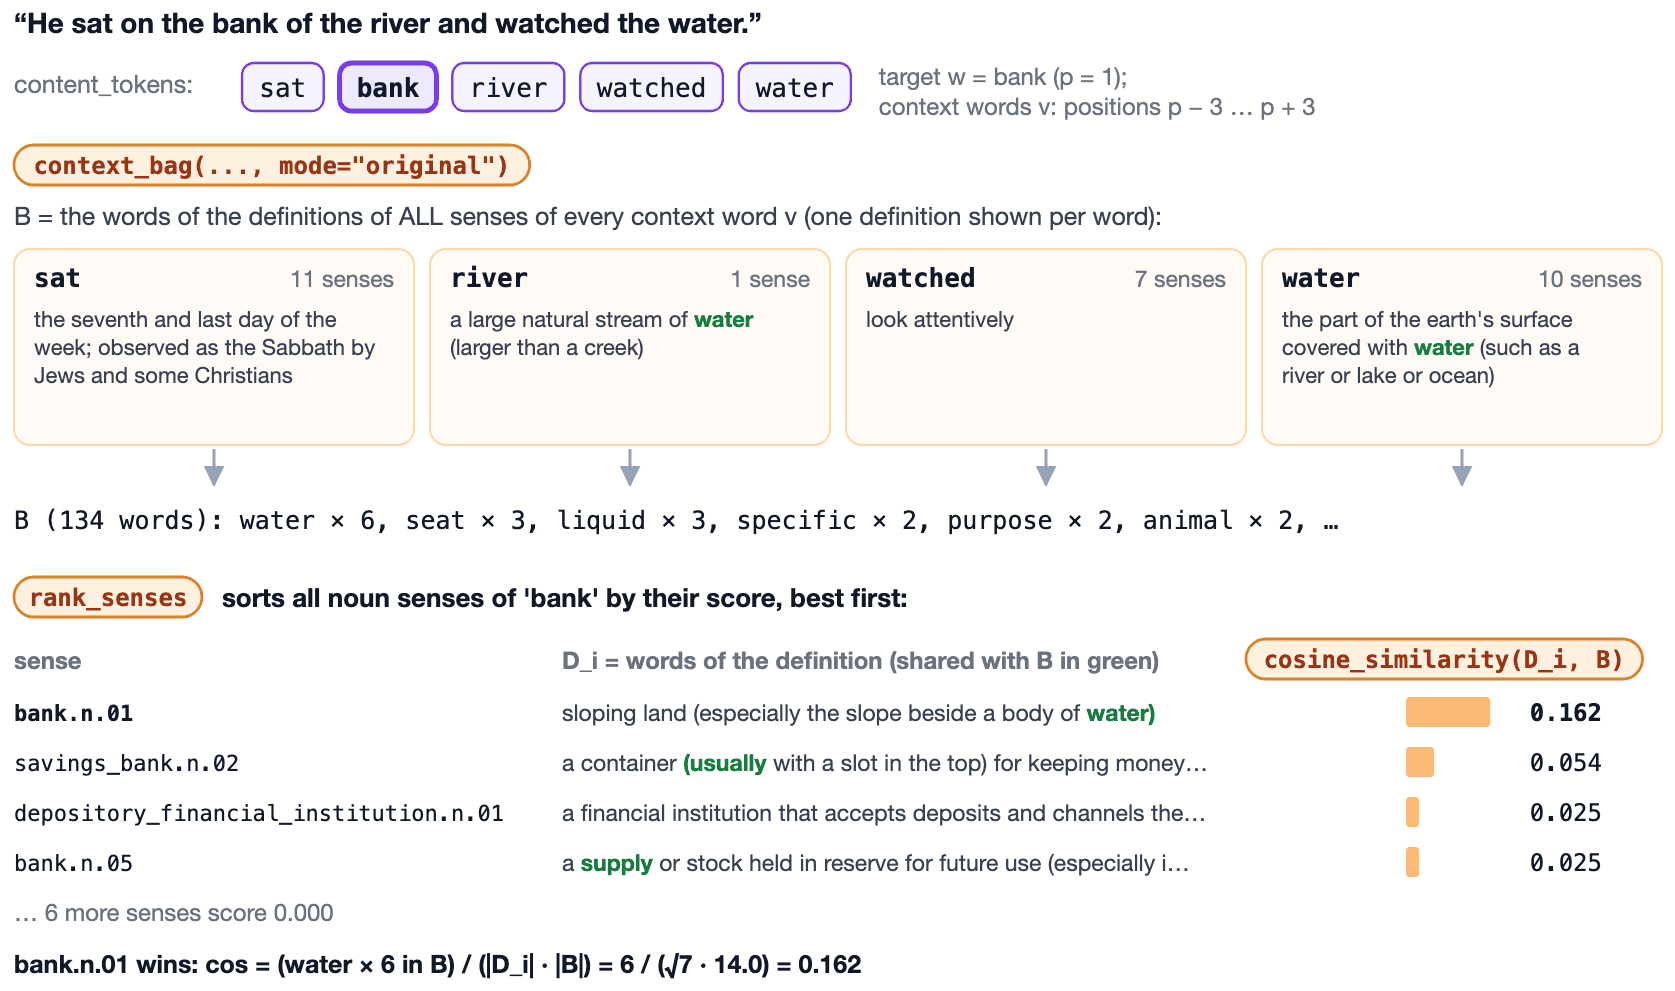

**Simplified Lesk:** the context words themselves form $B$.

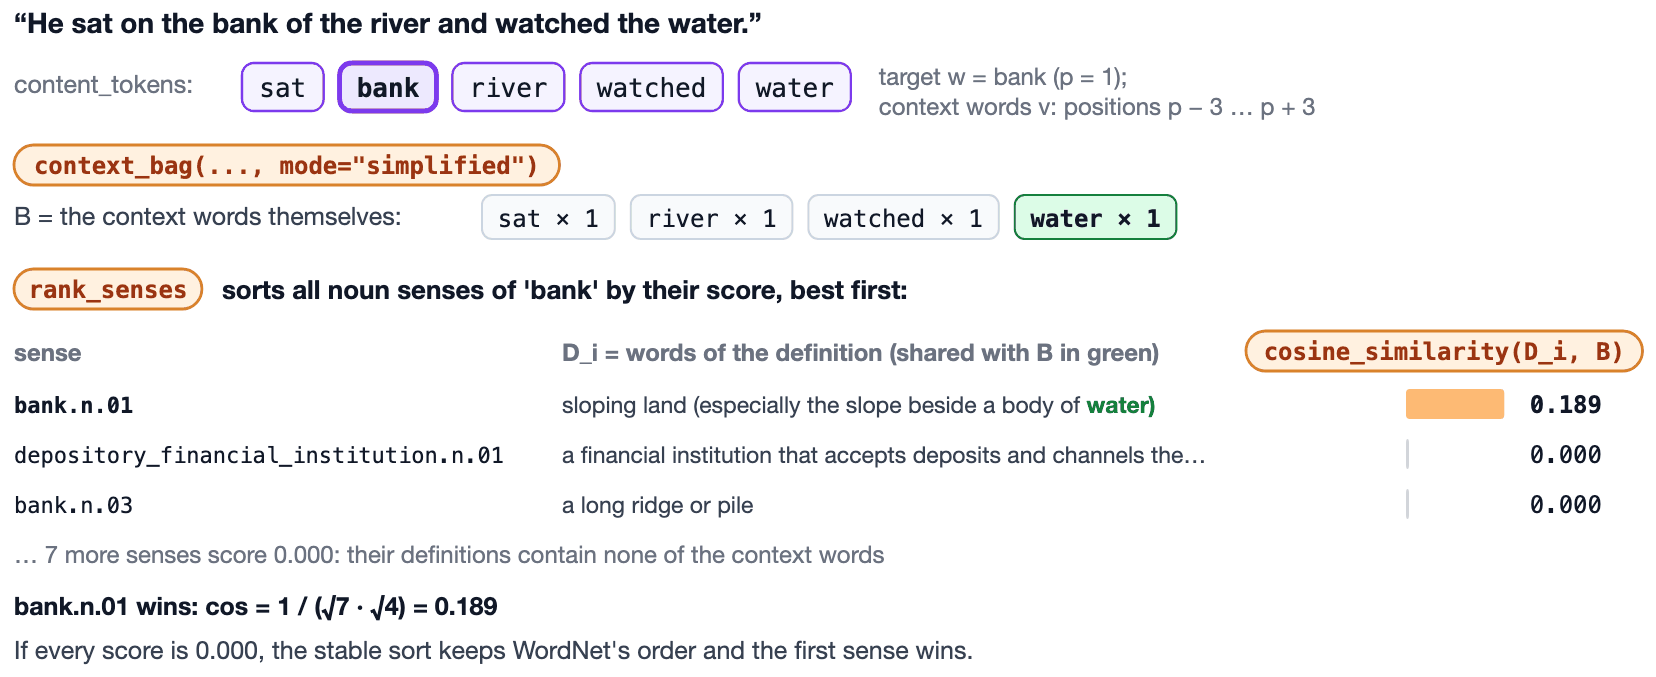

---

### What is provided
- `WSD_EXAMPLES`: 2,355 SemCor occurrences of 68 ambiguous nouns, e.g. `{"target": "interest", "sentence": "...", "gold": "interest.n.01"}`.
- `content_tokens(text)` (lowercase, alphabetic, no stopwords, noun lemmas from `WordNetLemmatizer` as in PS 02) and `all_sense_definitions(word)` (the definitions of all WordNet senses of a word).
- `evaluate_wsd(...)` and a random baseline.

---

### What you should implement
A bag of words is a `Counter` that maps each word to its count.
1) `cosine_similarity` — the formula above, computed directly on two bags; return a `float` between 0 and 1, and `0.0` if a bag is empty.
2) `context_bag` — return the bag $B$ (a `Counter`) for the content tokens of a sentence:
   - context words = the tokens at positions `p - window ... p + window`, where `p` is the **first** position of `target`, without position `p` and without any other token equal to `target`;
   - `mode="original"`: count the `content_tokens` of **every** definition in `all_sense_definitions(v)` for each context word `v` (a word that occurs twice counts twice);
   - `mode="simplified"`: count the context words themselves.
3) `rank_senses` — score every noun sense in `wn.synsets(target, pos=wn.NOUN)` by $\operatorname{CosSim}(D_i, B)$ with $D_i$ = `Counter(content_tokens(synset.definition()))`. Return a list of `(synset.name(), score)` tuples sorted by **descending** score; equal scores keep **WordNet's order** (use a stable sort).

---

### Grading (8 pts)
One sub-task per function above:
- **3.1** `cosine_similarity`, including empty bags — **2.5 pts**
- **3.2** `context_bag` in both modes — **3.0 pts**
- **3.3** `rank_senses`: all noun senses, descending scores, and on equal scores keep WordNet (`wn.synsets`) order; accuracies of both variants match the expected output — **2.5 pts**

> **Tips**
> • Only words that occur in both bags contribute to the inner product.
> • Build the sense list in `wn.synsets` order first, then sort by score descending. Then on ties it will keep WordNet order and your accuracies should match the expected output.

In [ ]:
def cosine_similarity(bag_a: Counter, bag_b: Counter) -> float:
    """Return the cosine similarity of two count vectors stored as Counters (0.0 for an empty bag)."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def context_bag(tokens: list[str], target: str, window: int = 3, mode: str = "original") -> Counter:
    """Return B: definitions of all senses of the context words ("original") or the words ("simplified")."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def rank_senses(target: str, sentence: str, window: int = 3,
                mode: str = "original") -> list[tuple[str, float]]:
    """Return (synset name, cosine score) for every noun sense, best first; ties keep WordNet order."""
    ## YOUR_CODE_STARTS_HERE
    pass
    ## YOUR_CODE_ENDS_HERE


def evaluate_wsd(examples: list[dict[str, str]], mode: str = "original") -> tuple[float, list[dict]]:
    """Predict the top-ranked sense of every example; return the accuracy and one record per example."""
    records = []
    for item in examples:
        predicted, score = rank_senses(item["target"], item["sentence"], window=3, mode=mode)[0]
        records.append({"target": item["target"], "gold": item["gold"], "predicted": predicted, "score": score})
    return float(np.mean([record["predicted"] == record["gold"] for record in records])), records


lesk_accuracy, lesk_records = evaluate_wsd(WSD_EXAMPLES, mode="original")
simplified_lesk_accuracy, simplified_lesk_records = evaluate_wsd(WSD_EXAMPLES, mode="simplified")
accuracies = {
    "random": random_baseline_accuracy(WSD_EXAMPLES),
    "original Lesk": lesk_accuracy,
    "simplified Lesk": simplified_lesk_accuracy,
}
for name, accuracy in accuracies.items():
    print(f"[TASK3] {name:<16} accuracy = {accuracy:.3f}")

bank_ranking = rank_senses("bank", "We sat by the bank watching the boats on the river.")
print("[TASK3] PS 02 example 'We sat by the bank watching the boats on the river.' (original Lesk, top 3):")
for name, score in bank_ranking[:3]:
    print(f"[TASK3]   {name:<12} {score:.3f}  {wn.synset(name).definition()}")

# RESULT_CHECKING_POINT
print(f"[TASK3 RESULT_CHECKING_POINT] Accuracy original vs simplified Lesk: "
      f"{lesk_accuracy:.3f} {simplified_lesk_accuracy:.3f}")

In [ ]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3] random           accuracy = 0.150
# [TASK3] original Lesk    accuracy = 0.215
# [TASK3] simplified Lesk  accuracy = 0.510
# [TASK3] PS 02 example 'We sat by the bank watching the boats on the river.' (original Lesk, top 3):
# [TASK3]   bank.n.01    0.102  sloping land (especially the slope beside a body of water)
# [TASK3]   savings_bank.n.02 0.068  a container (usually with a slot in the top) for keeping money at home
# [TASK3]   depository_financial_institution.n.01 0.000  a financial institution that accepts deposits and channels the money into lending activities
# [TASK3 RESULT_CHECKING_POINT] Accuracy original vs simplified Lesk: 0.215 0.510
#
# ---------------------------------------------------------------------------

# BONUS (2 pts): Solve one task with an LLM

**Goal.**
Choose **one** task (Task 1, Task 2, or Task 3), let an **LLM** solve it, run the LLM's code, and compare its result with the task's `TESTS & EXPECTED OUTPUT` cell and with your own solution.

**Steps.**
1. Give the LLM the task's description (the Markdown cell) and the code it depends on: the task's data-and-helpers cell and the task code cell with the empty `YOUR_CODE` regions. Ask it for the code of **all** functions you implement in that task.
2. Run the generated code in a **copy of this notebook**: paste it into the task code cell of the copy and run the copy from the top. This keeps your own solution here unchanged. Do not submit the copy.
3. Fill in the answer cell below.

**What to deliver in the answer cell.**
1) **LLM used**: (name + version, e.g., "Llama-3-8B-Instruct", "GPT-x", "Claude-x", "Mistral-x", etc.). You may use any LLMs through any interface (API, web UI, local inference).
2) **Generated code**: the LLM's generated code for the task's functions. If you needed several attempts, paste the last one.
3) **Output**: the `[TASKn RESULT_CHECKING_POINT]` line that the LLM's code printed, or the error message if it failed.
4) **Comparison and reflection** (3–6 sentences): Does the LLM's output match the expected output? Where does the LLM's code differ from your solution (e.g., a missing step, a different formula, extra code)? What did the LLM do well, and what did it get wrong?

**Grading (2 pts):**

- deliverables 1–3 complete — **1 pt**.
- deliverable 4: a brief comparison and reflection that says whether the LLM matched the expected output, how its code differs from yours, and what it did well vs wrong — **1 pt**

> **No code required for calling the LLM.** You do not need to submit your prompts or any code you used to call the LLM (e.g., API scripts). An LLM solution that fails can still earn the full bonus if you document and analyze its failure well in your **Comparison and reflection**. Provide only the deliverables listed above.

**1) LLM used (name and version):**

```
Claude Code Opus 5.5 (xHigh Thinking)  

```

**2) Generated code** (last attempt):

```python

```

**3) Output** (`[TASKn RESULT_CHECKING_POINT]` line or error message):

```text

```

**4) Comparison and reflection:**

```text

```

# End of HW 01

Before submitting, restart the runtime and run all cells. Confirm that your notebook contains your own work only.